# Part 1 - Blood cell classification

In [1]:
from pathlib import Path
import kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, Subset
from torch import optim, nn
import torch
import torchmetrics
import lightning as L
from lightning.pytorch.callbacks import EarlyStopping, ModelCheckpoint, TQDMProgressBar
from lightning.pytorch.loggers import CSVLogger
from sklearn.metrics import ConfusionMatrixDisplay
import random

RANDOM = 42
IMAGE_SIZE = 360
BATCH_SIZE = 32

random.seed(RANDOM)
np.random.seed(RANDOM)
torch.manual_seed(RANDOM)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'mps' if torch.backends.mps.is_available() else 'cpu')

print('Device:', DEVICE)

Device: mps


In [2]:
DATA = Path("data")
DATA.mkdir(exist_ok=True)

classification_download = Path(kagglehub.dataset_download(
  'unclesamulus/blood-cells-image-dataset',
  output_dir=str(DATA),
))

print(f"Dataset loaded to {classification_download}")

Dataset loaded to data


In [3]:
base_transform = transforms.Compose([
  transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
  transforms.ToTensor(),
])

dataset = datasets.ImageFolder(DATA / "bloodcells_dataset", transform=base_transform)
display(dataset)
n_classes = len(dataset.classes)
dataset.classes

Dataset ImageFolder
    Number of datapoints: 17092
    Root location: data/bloodcells_dataset
    StandardTransform
Transform: Compose(
               Resize(size=(360, 360), interpolation=bilinear, max_size=None, antialias=True)
               ToTensor()
           )

['basophil',
 'eosinophil',
 'erythroblast',
 'ig',
 'lymphocyte',
 'monocyte',
 'neutrophil',
 'platelet']

In [4]:
targets = dataset.targets
counts = pd.Series(np.bincount(targets), index=dataset.classes).sort_values()
counts

lymphocyte      1214
basophil        1218
monocyte        1420
erythroblast    1551
platelet        2348
ig              2895
eosinophil      3117
neutrophil      3329
dtype: int64

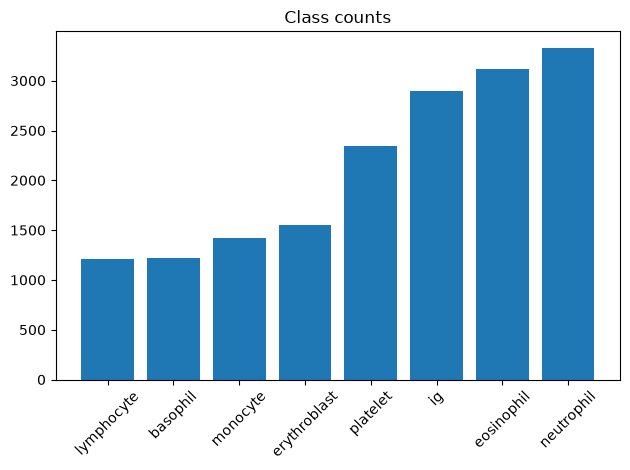

In [5]:
plt.bar(counts.index, counts.values)
plt.title('Class counts')
plt.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

In [6]:
idx = np.arange(len(dataset))
targets = np.asarray(dataset.targets)

train_idx, valtest_idx = train_test_split(
  idx,
  test_size=0.2,
  stratify=dataset.targets,
  random_state=RANDOM,
)

temp = targets[valtest_idx]
val_idx, test_idx = train_test_split(
  valtest_idx,
  test_size=0.5,
  stratify=temp,
  random_state=RANDOM,
)

train_dataset = Subset(dataset, train_idx)
val_dataset = Subset(dataset, val_idx)
test_dataset = Subset(dataset, test_idx)

loader_kwargs = dict(batch_size=BATCH_SIZE, num_workers=4, persistent_workers=True)

train_loader = DataLoader(train_dataset, shuffle=True, **loader_kwargs)
val_loader = DataLoader(val_dataset, **loader_kwargs)
test_loader = DataLoader(test_dataset, **loader_kwargs)

print('Split sizes:', len(train_dataset), len(val_dataset), len(test_dataset))

Split sizes: 13673 1709 1710


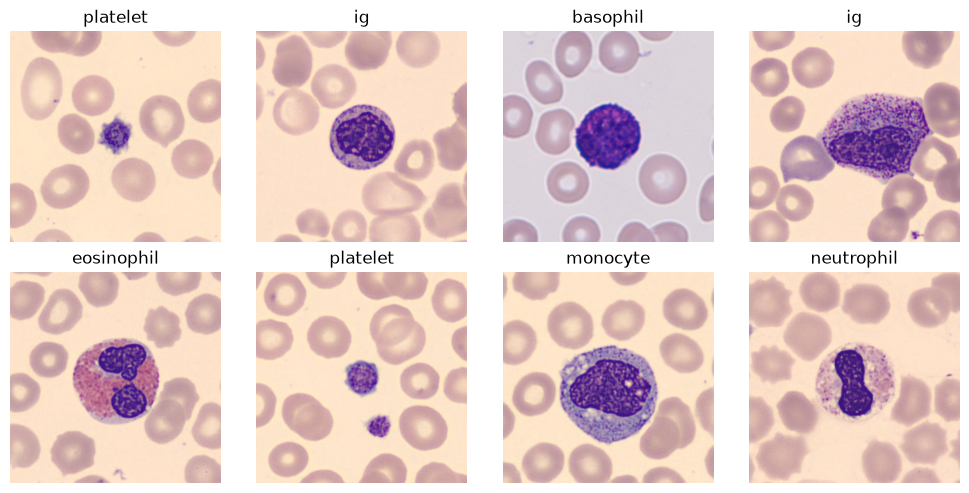

In [7]:
batch_images, batch_labels = next(iter(train_loader))

figure, axes = plt.subplots(2, 4, figsize=(10, 5))
for axis, image, label in zip(axes.ravel(), batch_images[:8], batch_labels[:8]):
  axis.imshow(image.permute(1, 2, 0).numpy())
  axis.set_title(dataset.classes[int(label)])
  axis.axis('off')

plt.tight_layout()
plt.show()

In [8]:
class Model(L.LightningModule):
  def __init__(self, model, loss, metrics, lr=1e-3):
    super().__init__()
    self.model = model
    self.loss = loss
    self.lr = lr

    metrics = torchmetrics.MetricCollection(metrics)
    self.val_metrics = metrics.clone(prefix="val_")
    self.test_metrics = metrics.clone(prefix="test_")

  def training_step(self, batch):
    X, y = batch
    y_hat = self.model(X)
    loss = self.loss(y_hat, y)
    self.log("train_loss", loss, on_epoch=True, prog_bar=True)
    return loss

  def validation_step(self, batch):
    X, y = batch
    y_hat = self.model(X)
    self.log("val_loss", self.loss(y_hat, y), prog_bar=True)
    self.val_metrics(y_hat, y)
    self.log_dict(self.val_metrics, prog_bar=True)

  def test_step(self, batch):
    X, y = batch
    y_hat = self.model(X)
    self.log("test_loss", self.loss(y_hat, y))
    self.test_metrics(y_hat, y)
    self.log_dict(self.test_metrics)

  def configure_optimizers(self):
    optimizer = optim.Adam(self.parameters(), lr=self.lr)
    return optimizer

In [9]:
metrics = {
  "acc": torchmetrics.Accuracy(
    task="multiclass",
    average="macro",
    num_classes=n_classes,
  ),
  "f1": torchmetrics.F1Score(
    task="multiclass",
    average="macro",
    num_classes=n_classes,
  ),
}

loss = nn.CrossEntropyLoss()

In [10]:
def make_trainer(name):
  logger = CSVLogger("logs", name=name)
  trainer = L.Trainer(
    max_epochs=50,
    logger=logger,
    callbacks=[
      EarlyStopping(
        monitor="val_loss",
        mode="min",
        patience=5,
        min_delta=1e-3,
      ),
      ModelCheckpoint(
        monitor="val_loss",
        mode="min",
        save_top_k=1,
      ),
      TQDMProgressBar(refresh_rate=20),
    ]
  )

  return trainer

def show_history(trainer):
  history = pd.read_csv(Path(trainer.logger.log_dir) / "metrics.csv")
  per_epoch = history.groupby("epoch").mean()

  fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
  per_epoch[["train_loss_epoch", "val_loss"]].plot(ax=ax1, marker="o", title="Loss")
  per_epoch[["val_acc", "val_f1"]].plot(ax=ax2, marker="o", title="Validation scores")
  fig.show()

def show_confusion_matrix(model):
  model.eval()
  preds, labels = [], []
  with torch.no_grad():
    for X, y in test_loader:
      preds.append(model.model(X.to(model.device)).argmax(1).cpu())
      labels.append(y)

  ConfusionMatrixDisplay.from_predictions(
    torch.cat(labels),
    torch.cat(preds),
    display_labels=dataset.classes,
    normalize="true",
    values_format=".2f",
    xticks_rotation=45,
  )
  plt.show()

def train(model, name, train_loader, val_loader, test_loader):
  trainer = make_trainer(name)
  trainer.fit(model, train_loader, val_loader)
  trainer.test(model, test_loader)
  show_history(trainer)
  show_confusion_matrix(model)

def count_parameters(model):
  return sum(parameter.numel() for parameter in model.parameters() if parameter.requires_grad)

In [11]:
class SimpleCNN(nn.Module):
  def __init__(self, n_classes, in_channels=3, image_size=IMAGE_SIZE):
    super().__init__()

    self.features = nn.Sequential(
      nn.Conv2d(in_channels, 16, kernel_size=3, padding=1),
      nn.ReLU(),
      nn.MaxPool2d(2),
      nn.Conv2d(16, 32, kernel_size=3, padding=1),
      nn.ReLU(),
      nn.MaxPool2d(2),
    )

    reduced = image_size // 4

    self.classifier = nn.Sequential(
      nn.Flatten(),
      nn.Linear(32 * reduced * reduced, n_classes),
    )

  def forward(self, X):
    X = self.features(X)
    y = self.classifier(X)
    return y

In [16]:
cnn = SimpleCNN(n_classes)
print(cnn)
print('Trainable parameters:', count_parameters(cnn))

SimpleCNN(
  (features): Sequential(
    (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=259200, out_features=8, bias=True)
  )
)
Trainable parameters: 2078696


GPU available: True (mps), used: True
TPU available: False, using: 0 TPU cores


💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


┏━━━┳━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name         ┃ Type             ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ model        │ SimpleCNN        │  2.1 M │ train │     0 │
│ 1 │ loss         │ CrossEntropyLoss │      0 │ eval  │     0 │
│ 2 │ val_metrics  │ MetricCollection │      0 │ train │     0 │
│ 3 │ test_metrics │ MetricCollection │      0 │ train │     0 │
└───┴──────────────┴──────────────────┴────────┴───────┴───────┘

Trainable params: 2.1 M                                                                                            
Non-trainable params: 0                                                                                            
Total params: 2.1 M                                                                                                
Total estimated model params size (MB): 8.315                                                                      
Modules in train mode: 17                                                                                          
Modules in eval mode: 1                                                                                            
Total FLOPs: 0

Sanity Checking: |          | 0/? [00:00<?, ?it/s]

/Users/alegator1209/Documents/KSE/term-4/ml/ml_bio_hw/.venv/lib/python3.11/site-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
/Users/alegator1209/Documents/KSE/term-4/ml/ml_bio_hw/.venv/lib/python3.11/site-packages/lightning/pytorch/loops/fit_loop.py:538: Found 1 module(s) in eval mode at the start of training. This may lead to unexpected behavior during training. If this is intentional, you can ignore this warning.


... (9 outputs left out)

Validation: |          | 0/? [00:00<?, ?it/s]

Testing: |          | 0/? [00:00<?, ?it/s]

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃        Test metric        ┃       DataLoader 0        ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│         test_acc          │    0.8989880084991455     │
│          test_f1          │     0.908852219581604     │
│         test_loss         │    0.32853955030441284    │
└───────────────────────────┴───────────────────────────┘

/var/folders/m7/qn99csmd48s9232z_r7d50nw0000gn/T/ipykernel_34662/2933990092.py:31: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


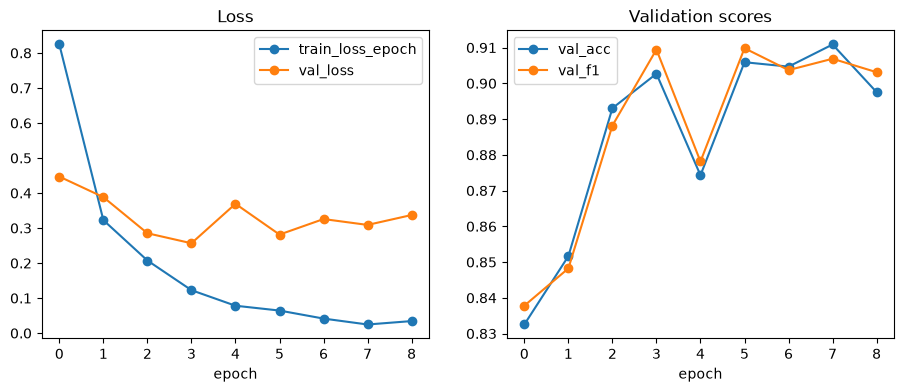

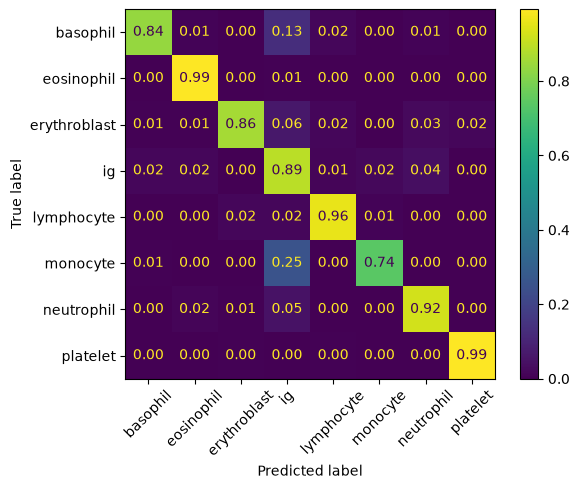

In [ ]:
train(Model(cnn, loss, metrics), "simple_cnn", train_loader, val_loader, test_loader)

In [18]:
class DeeperCNN(nn.Module):
  def __init__(self, n_classes, in_channels=3, image_size=IMAGE_SIZE):
    super().__init__()

    self.features = nn.Sequential(
      nn.Conv2d(in_channels, 16, kernel_size=3, padding=1),
      nn.ReLU(),
      nn.MaxPool2d(2),
      nn.Conv2d(16, 32, kernel_size=3, padding=1),
      nn.ReLU(),
      nn.MaxPool2d(2),
      nn.Conv2d(32, 16, kernel_size=3, padding=1),
      nn.ReLU(),
      nn.MaxPool2d(2),
    )

    reduced = image_size // 8

    self.classifier = nn.Sequential(
      nn.Flatten(),
      nn.Linear(16 * reduced * reduced, n_classes),
    )

  def forward(self, X):
    X = self.features(X)
    y = self.classifier(X)
    return y

GPU available: True (mps), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


DeeperCNN(
  (features): Sequential(
    (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(32, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=32400, out_features=8, bias=True)
  )
)
Trainable parameters: 268920


┏━━━┳━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name         ┃ Type             ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ model        │ DeeperCNN        │  268 K │ train │     0 │
│ 1 │ loss         │ CrossEntropyLoss │      0 │ eval  │     0 │
│ 2 │ val_metrics  │ MetricCollection │      0 │ train │     0 │
│ 3 │ test_metrics │ MetricCollection │      0 │ train │     0 │
└───┴──────────────┴──────────────────┴────────┴───────┴───────┘

Trainable params: 268 K                                                                                            
Non-trainable params: 0                                                                                            
Total params: 268 K                                                                                                
Total estimated model params size (MB): 1.076                                                                      
Modules in train mode: 20                                                                                          
Modules in eval mode: 1                                                                                            
Total FLOPs: 0

Sanity Checking: |          | 0/? [00:00<?, ?it/s]

/Users/alegator1209/Documents/KSE/term-4/ml/ml_bio_hw/.venv/lib/python3.11/site-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
/Users/alegator1209/Documents/KSE/term-4/ml/ml_bio_hw/.venv/lib/python3.11/site-packages/lightning/pytorch/loops/fit_loop.py:538: Found 1 module(s) in eval mode at the start of training. This may lead to unexpected behavior during training. If this is intentional, you can ignore this warning.


... (12 outputs left out)

Validation: |          | 0/? [00:00<?, ?it/s]

Testing: |          | 0/? [00:00<?, ?it/s]

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃        Test metric        ┃       DataLoader 0        ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│         test_acc          │    0.8738054037094116     │
│          test_f1          │    0.8773375749588013     │
│         test_loss         │    0.3864566683769226     │
└───────────────────────────┴───────────────────────────┘

/var/folders/m7/qn99csmd48s9232z_r7d50nw0000gn/T/ipykernel_34662/2933990092.py:31: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


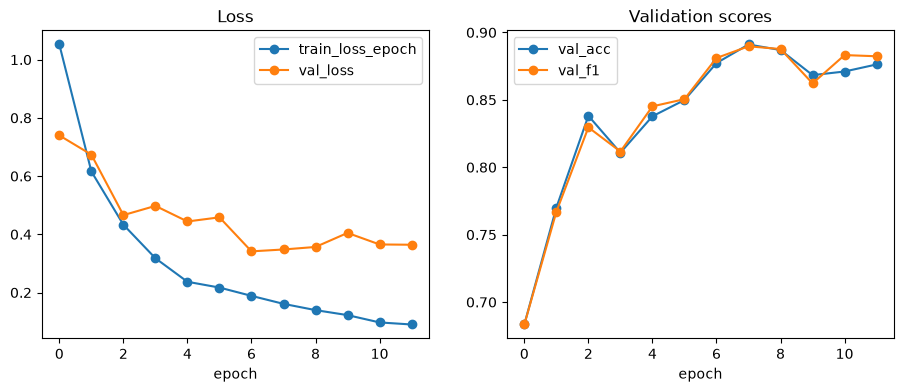

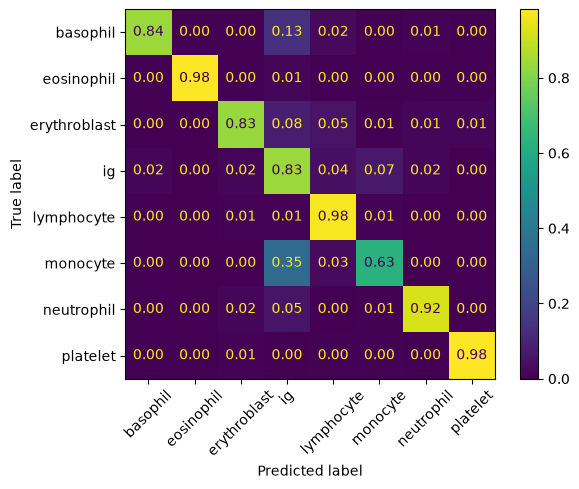

In [ ]:
deeper_cnn = DeeperCNN(n_classes)
print(deeper_cnn)
print('Trainable parameters:', count_parameters(deeper_cnn))
train(Model(deeper_cnn, loss, metrics), "deeper_cnn", train_loader, val_loader, test_loader)

In [12]:
augmented_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
])

aug_dataset = datasets.ImageFolder(DATA / "bloodcells_dataset", transform=augmented_transform)
aug_train_loader = DataLoader(Subset(aug_dataset, train_idx), shuffle=True, **loader_kwargs)

GPU available: True (mps), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


SimpleCNN(
  (features): Sequential(
    (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=259200, out_features=8, bias=True)
  )
)
Trainable parameters: 2078696


┏━━━┳━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name         ┃ Type             ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ model        │ SimpleCNN        │  2.1 M │ train │     0 │
│ 1 │ loss         │ CrossEntropyLoss │      0 │ train │     0 │
│ 2 │ val_metrics  │ MetricCollection │      0 │ train │     0 │
│ 3 │ test_metrics │ MetricCollection │      0 │ train │     0 │
└───┴──────────────┴──────────────────┴────────┴───────┴───────┘

Trainable params: 2.1 M                                                                                            
Non-trainable params: 0                                                                                            
Total params: 2.1 M                                                                                                
Total estimated model params size (MB): 8.315                                                                      
Modules in train mode: 18                                                                                          
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Sanity Checking: |          | 0/? [00:00<?, ?it/s]

/Users/alegator1209/Documents/KSE/term-4/ml/ml_bio_hw/.venv/lib/python3.11/site-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


... (25 outputs left out)

Validation: |          | 0/? [00:00<?, ?it/s]

Testing: |          | 0/? [00:00<?, ?it/s]

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃        Test metric        ┃       DataLoader 0        ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│         test_acc          │    0.9264466762542725     │
│          test_f1          │     0.924008846282959     │
│         test_loss         │    0.24870604276657104    │
└───────────────────────────┴───────────────────────────┘

/var/folders/m7/qn99csmd48s9232z_r7d50nw0000gn/T/ipykernel_59143/859895217.py:31: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


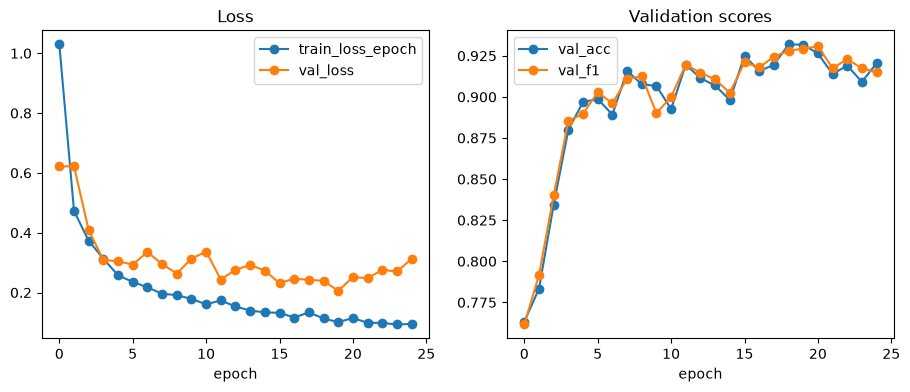

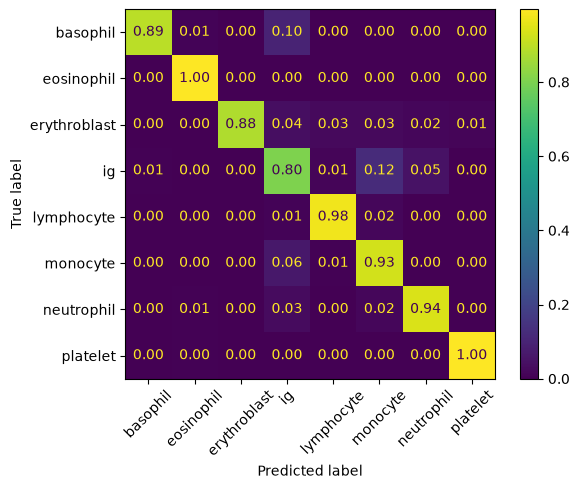

In [13]:
aug_cnn = SimpleCNN(n_classes)
print(aug_cnn)
print('Trainable parameters:', count_parameters(aug_cnn))
train(
  Model(aug_cnn, loss, metrics),
  "simple_cnn_aug",
  aug_train_loader,
  val_loader,
  test_loader,
)

# Conclusion

All three models achieved high level of test accuracy:

| Metric  | SimpleCNN | DeeperCNN | AugSimpleCNN |
|---------|-----------|-----------|--------------|
| Acc     | 0.899     | 0.874     | 0.926        |
| F1      | 0.909     | 0.877     | 0.924        |
| CE Loss | 0.329     | 0.386     | 0.249        |

DeeperCNN, with additional convolution layer, downscaling 32 channels to 16, showed degraded performance but offered gigantic savings in term of parameters (2.1M vs 268K) which, on my mind, justifies the 2.5% accuracy drop.

Input data augmentation showed the best results with 92.6% accuracy and F1 = 0.924. The most remarkable achievement of this method though, is that it fixed problem with Monocytes which other two models often mistaked for Immature Granulocytes. Given the lower number of Monocytes in the input data, compared to IGs, flip and rotation augmentations filled this gap and helped the model to distinguish them better. For comparison: in normal training 13% of Basophils and 25% of Monocytes were assigned IG class. In the augmented experiment, only 10% of Basophils and 6% of Monocytes are mislabeled to IGs.

The best perspective for future work is probably DeeperCNN + augmentation to utilize both parameter savings and increased accuracy from synthetic data. We won't do it here though, because deadlines are many and we are few.